<a href="https://colab.research.google.com/github/sambhavi298/LDA/blob/main/LDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [ ]:
data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = pd.Series(
    data.target,
    name="Target"
)

print("Dataset loaded successfully.")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Dataset loaded successfully.
Number of samples: 569
Number of features: 30


In [ ]:
print("First 5 rows:")
display(X.head())

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
print("\nTarget values:")
print(y.head())


Target values:
0    0
1    0
2    0
3    0
4    0
Name: Target, dtype: int64


In [ ]:
print("Dataset Information")
print("=" * 50)

print("\nShape:", X.shape)

print("\nData Types:")
print(X.dtypes)

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nDuplicate Rows:", X.duplicated().sum())

Dataset Information

Shape: (569, 30)

Data Types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
wors

In [ ]:
print("Class Distribution:")
print(y.value_counts())

print("\nClass Names:")
print("0 =", data.target_names[0])
print("1 =", data.target_names[1])

Class Distribution:
Target
1    357
0    212
Name: count, dtype: int64

Class Names:
0 = malignant
1 = benign


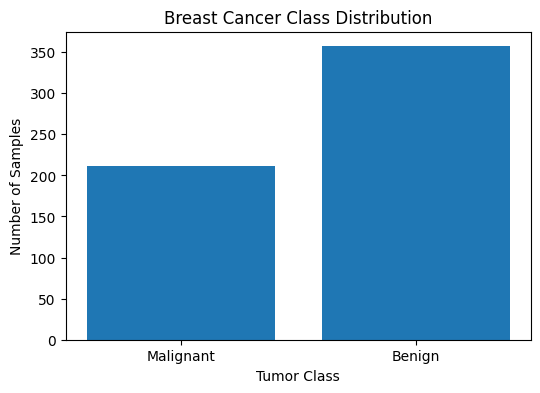

In [ ]:
plt.figure(figsize=(6, 4))

counts = y.value_counts().sort_index()

plt.bar(
    ["Malignant", "Benign"],
    counts.values
)

plt.xlabel("Tumor Class")
plt.ylabel("Number of Samples")
plt.title("Breast Cancer Class Distribution")

plt.show()

In [ ]:
print("Statistical Summary:")
display(X.describe().T)

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


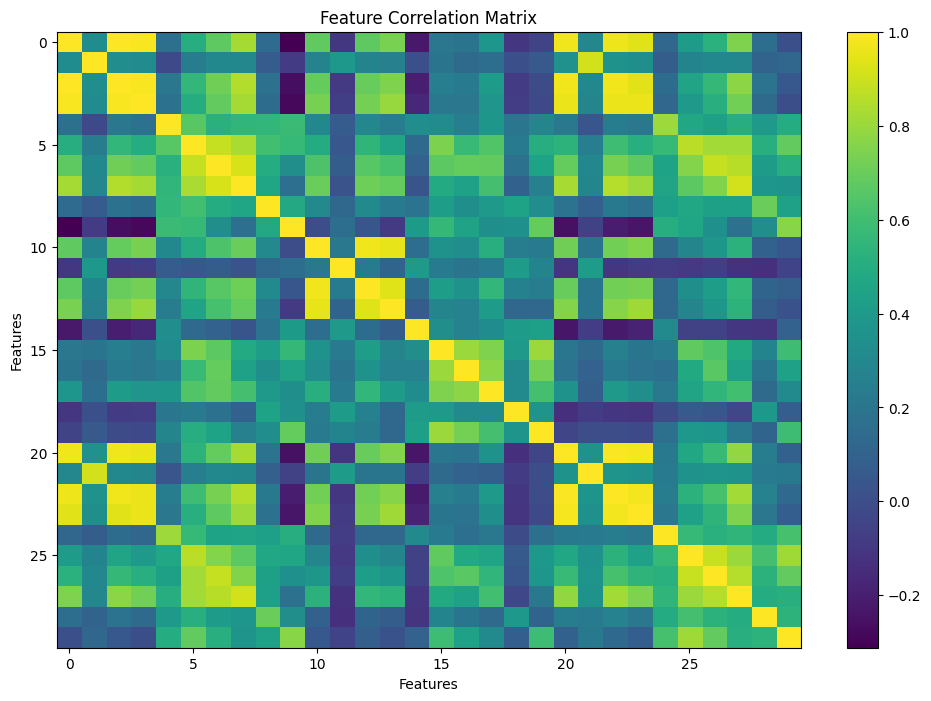

In [ ]:
correlation = X.corr()

plt.figure(figsize=(12, 8))

plt.imshow(correlation, aspect="auto")

plt.colorbar()

plt.title("Feature Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Features")

plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
lda_model = LinearDiscriminantAnalysis()

lda_model.fit(X_train_scaled, y_train)

print("LDA model trained successfully.")

LDA model trained successfully.


In [ ]:
y_pred = lda_model.predict(X_test_scaled)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]

Predicted values:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[38  4]
 [ 1 71]]


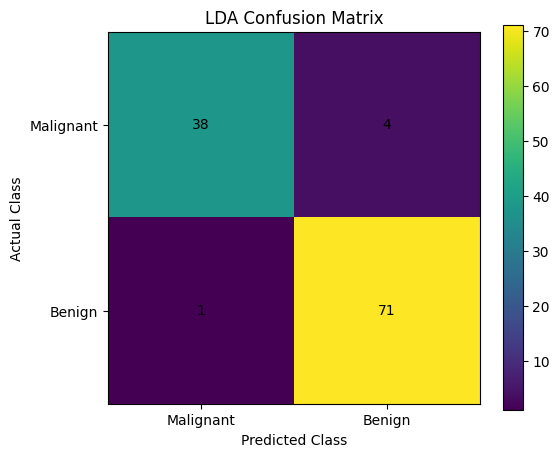

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("LDA Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Malignant", "Benign"]
)

plt.yticks(
    [0, 1],
    ["Malignant", "Benign"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 95.61%


In [ ]:
precision = precision_score(
    y_test,
    y_pred
)

print(f"Precision: {precision * 100:.2f}%")

Precision: 94.67%


In [ ]:
recall = recall_score(
    y_test,
    y_pred
)

print(f"Recall: {recall * 100:.2f}%")

Recall: 98.61%


In [ ]:
malignant_recall = recall_score(
    y_test,
    y_pred,
    pos_label=0
)

print(
    f"Malignant Recall: {malignant_recall * 100:.2f}%"
)

Malignant Recall: 90.48%


In [ ]:
f1 = f1_score(
    y_test,
    y_pred
)

print(f"F1 Score: {f1 * 100:.2f}%")

F1 Score: 96.60%


In [ ]:
print("Classification Report")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"]
    )
)

Classification Report
              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



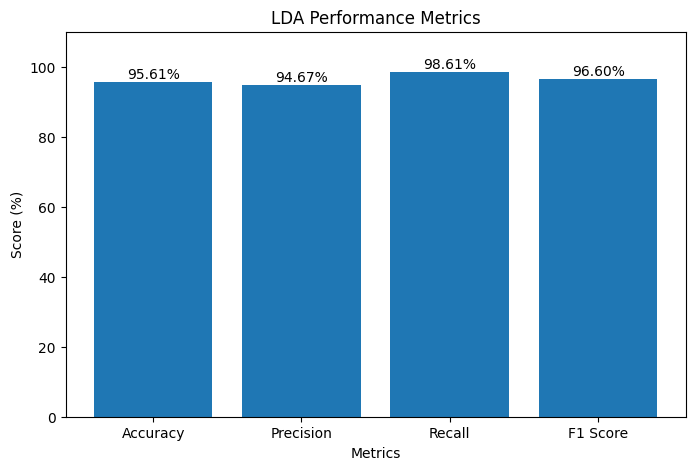

In [ ]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

plt.figure(figsize=(8, 5))

values = [v * 100 for v in metrics.values()]

plt.bar(
    metrics.keys(),
    values
)

plt.xlabel("Metrics")
plt.ylabel("Score (%)")
plt.title("LDA Performance Metrics")
plt.ylim(0, 110)

for i, value in enumerate(values):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

In [ ]:
X_lda = lda_model.transform(X_test_scaled)

print("Original number of features:", X_test_scaled.shape[1])
print("LDA components:", X_lda.shape[1])

Original number of features: 30
LDA components: 1


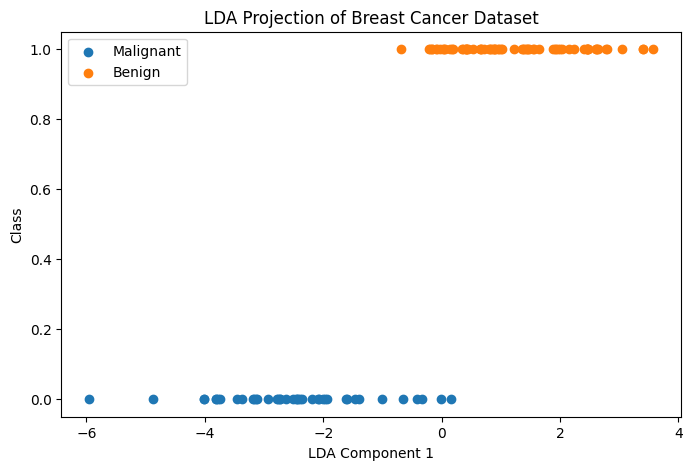

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_lda[y_test.values == 0],
    np.zeros(sum(y_test.values == 0)),
    label="Malignant"
)

plt.scatter(
    X_lda[y_test.values == 1],
    np.ones(sum(y_test.values == 1)),
    label="Benign"
)

plt.xlabel("LDA Component 1")
plt.ylabel("Class")
plt.title("LDA Projection of Breast Cancer Dataset")
plt.legend()

plt.show()

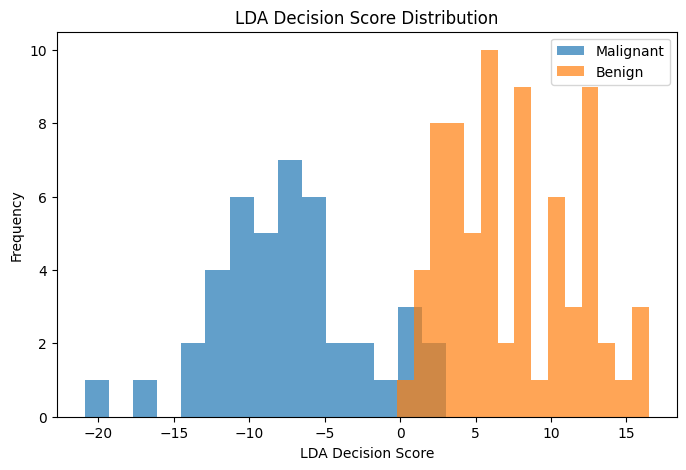

In [ ]:
decision_scores = lda_model.decision_function(X_test_scaled)

plt.figure(figsize=(8, 5))

plt.hist(
    decision_scores[y_test.values == 0],
    bins=15,
    alpha=0.7,
    label="Malignant"
)

plt.hist(
    decision_scores[y_test.values == 1],
    bins=15,
    alpha=0.7,
    label="Benign"
)

plt.xlabel("LDA Decision Score")
plt.ylabel("Frequency")
plt.title("LDA Decision Score Distribution")
plt.legend()

plt.show()